# Function 7: pooled cohort observation review

**Side quest — 20 October 2026.** A copy of the [Week 4 notebook](../../../../../notebooks/Function_7/Week_04/observation_review.ipynb),
using **38 observations**: 30 shared initial points,
3 confirmed own returns and **5 additional peer records**.
The methods, target treatments and search settings are retained. Peer data are
published reports, not independently verified portal returns. See the
[dataset audit](../../../dataset-audit.json) for exact sources and exclusions.

Week 4 has already been submitted. Any original coverage plan is a historical
reference; any newly calculated suggestion here is hypothetical. This pooled
snapshot includes records collected later, so its validation is not a forecast
made before the original Week 3 return. Query-budget numbers refer to the
original start of Week 4 and confer no additional evaluation allowance.


## Function description and cohort clues

**Course description, paraphrased.** Tune six ML hyperparameters to maximise a performance score. The lesson suggests established modelling practice as a possible guide to the search.

Source: [Mini-lesson 12.8: function descriptions](https://classroom.emeritus.org/courses/18642/modules/items/3237303), reviewed
20 October 2026. The notes below interpret the fixed cohort snapshot collected
on that date. Peer outputs are published reports, not independently verified
portal returns. Every official objective remains maximisation of signed y.

### What the cohort observations suggest

The **38 observations** show a strong measured neighbourhood. The eight highest
records have **x1 ≤ 0.058** and **x6 ≈ 0.70–0.78**. The best two keep x4 near
**0.285**, with intermediate settings for x2, x3 and x5. Low x1 alone does not
establish a good six-input combination.

| Own evidence | Best output |
| --- | ---: |
| Shared initial observations | 1.364968 |
| Round 1 | 1.405759 |
| Round 2 | 2.075222 |
| Round 3 | 2.552418 |

The latest two own returns are the highest in this pooled snapshot. At portal
precision, the first query changed only x4, from **0.218118 to 0.318118**, raising
the score by **0.040791**. Later larger gains changed several coordinates together
and cannot be attributed to a single input. Several peer queries also target
the initial strong neighbourhood; this selected cluster does not cover the domain.

### Exploration implication

Continue examining the low-x1 neighbourhood, including the balance among x2,
x3 and x5 with x6 around 0.7. Literature would be more actionable with the actual
model identity and parameter definitions: the examples do not identify x1 as a
learning rate or supply a column mapping. Scores above 1 also mean the returned
scale is not literal unscaled accuracy or F1. No single-peak guarantee is given.

These patterns describe selected observations, not controlled causal effects or a known true surface. Exploration suggestions are hypotheses for the side quest, not submissions.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_7/Week_04 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish the pooled evidence

The common supplied observations form one initial batch. Later rows retain
the round reported in each peer history; an ordered history without explicit
round numbers uses its recorded query order. Coverage across repositories is
incomplete. Several returned queries can belong to the same round.

In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 7.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 30, 1: 4, 2: 3, 3: 1}:
    raise ValueError("This review expects the fixed Week 4 snapshot through round 3.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 4"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Published completed rounds: {returned.source_round.nunique()}; pooled returned queries: {len(returned)}")

,Evidence,Count
0,Input dimensions,6
1,Initial observations,30
2,Returned queries,8
3,Total observations,38
4,"Queries available, including Week 4",10


Published completed rounds: 3; pooled returned queries: 8


## 2. Place the latest recorded round among the pooled outputs

The own round 3 return is **2.55242**, ranked **1/38 (1 = highest)**
in the pooled data. The best published output is **2.55242** from
`round-03`. These rankings describe the available records, with
the precision and reporting limitations documented in the audit.

In [3]:
print(output_review["report"])

Latest recorded submission: round 3 (1 new output).
Compared with 37 earlier observations (38 outputs in total).
Earlier output range: [0.002701, 2.07522183931].

round-03: y = 2.55241765269 (positive); rank 1/38 (1 = highest output).
Inputs: x1 = 0.018718, x2 = 0.312926, x3 = 0.370268, x4 = 0.285721, x5 = 0.308321, x6 = 0.69567
New highest observed output. Largest absolute magnitude so far (1.23 times the earlier largest).


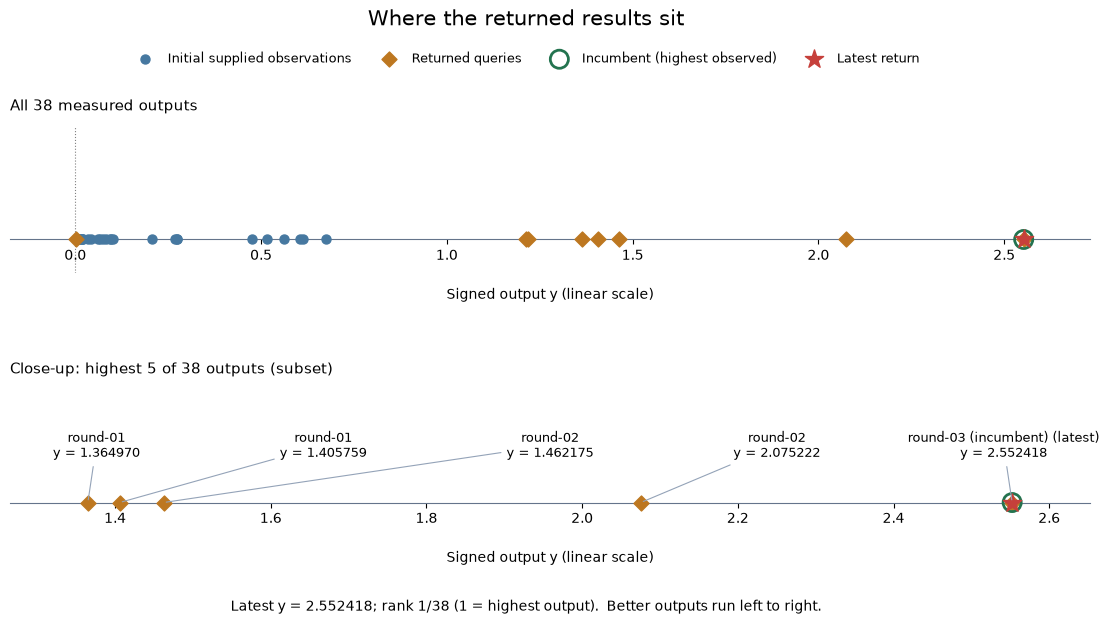

In [4]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

The full number line retains all 38 measured/reported outputs. The
close-up labels the highest five, retaining their actual spacing. Moving right
means a higher output. This selected sample does not estimate the distribution
of outputs across the domain. A missing peer return is not a zero.

## 3. Track the best published output across rounds

For each reported round, show its highest returned output and the best seen
through that round. Several peers can contribute; this is a pooled record,
not a measure of one person's strategy. Repository coverage is incomplete.

In [5]:
running_best = float(initial['y'].max())
progress_rows = [{'source_round': 0, 'stage': 'Initial batch', 'returned_y': np.nan,
                  'best_y': running_best, 'change_vs_prior_best': np.nan}]
for round_number, group in returned.groupby('source_round', sort=True):
    value = float(group['y'].max())
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({'source_round': int(round_number), 'stage': f'Round {round_number}',
                          'returned_y': value, 'best_y': running_best,
                          'change_vs_prior_best': change})
progress = pd.DataFrame(progress_rows)
display(progress.set_index('stage').style.format(precision=6, na_rep='—'))


,source_round,returned_y,best_y,change_vs_prior_best
stage,,,,
Initial batch,0,—,1.364968,—
Round 1,1,1.405759,1.405759,0.040791
Round 2,2,2.075222,2.075222,0.669463
Round 3,3,2.552418,2.552418,0.477196


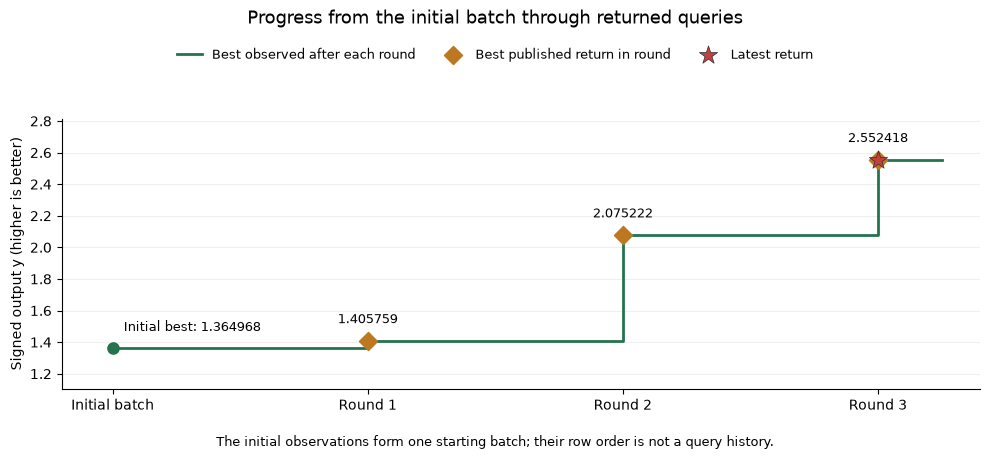

In [6]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

The pooled incumbent changes from **1.36497** in the
shared initial data to **2.55242**. The own-data incumbent
is **2.55242**. Access to other people's experiments changes
the evidence budget, so this comparison cannot demonstrate that our strategy
outperformed theirs, or vice versa.

## 4. Examine the strongest input combinations

Keep all six coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [7]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,x5,x6,y
observation_id,,,,,,,,,
round-03,1,3,0.018718,0.312926,0.370268,0.285721,0.308321,0.695670,2.552418
round-02,2,2,0.015118,0.386113,0.305380,0.283890,0.363300,0.714745,2.075222
peer-kosina-round-02,3,2,0.000000,0.491672,0.247422,0.250718,0.394579,0.698452,1.462175
round-01,4,1,0.057896,0.491672,0.247422,0.318118,0.420428,0.730970,1.405759
peer-tomxandrews-round-01,5,1,0.050000,0.485000,0.255000,0.210000,0.430000,0.745000,1.364970


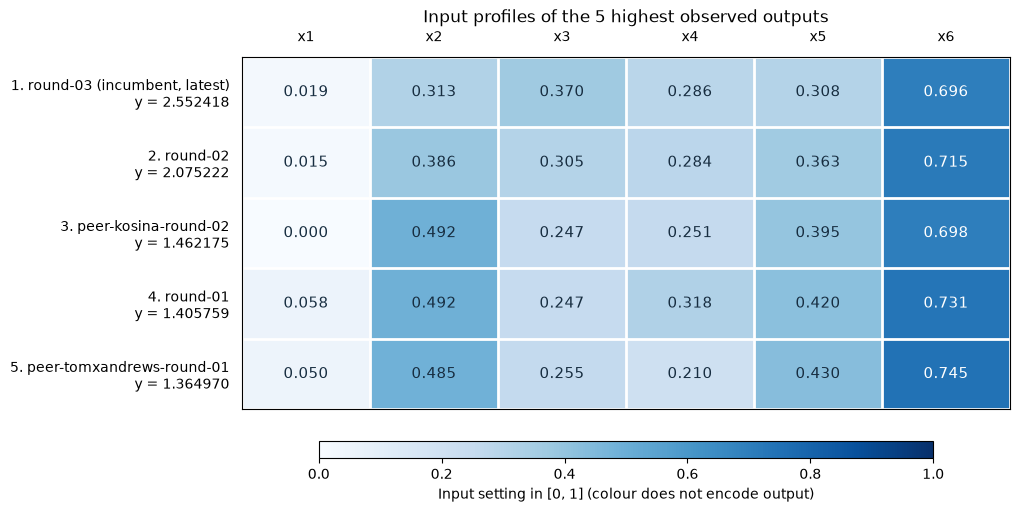

In [8]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

Read each row as one complete measured/reported combination. The input
colours describe settings, while the row label reports its output. Rows can
have very different performance even when neighbouring in rank. Compare all
coordinates before suggesting a pattern; these are not controlled tests of
one input at a time.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [9]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full six-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.015118,0.018718,0.003600
x2,0.386113,0.312926,-0.073187
x3,0.305380,0.370268,0.064888
x4,0.283890,0.285721,0.001831
x5,0.363300,0.308321,-0.054979
x6,0.714745,0.695670,-0.019075


Previous best: round-02; y = 2.075222
Full six-input distance to previous best: 0.113884
Latest output minus previous best: +0.477196
Nearest earlier observation: round-02 (distance 0.113884)
Repeated full input combinations: 0


The full-input distance and output difference above compare the own round 3
query with the best published record from earlier reported rounds. Distances
do not identify causal effects or account for differing input relevance.
Published precision and potential reporting mistakes remain limitations.

## 5. Continue with the pooled model study

Open [model predictions](model_predictions.ipynb) to compare the same methods
on this larger dataset, inspect held-out errors and uncertainty, and calculate
a hypothetical query. The official submission is unchanged.

**Provenance:** the audit retains commit-pinned GitHub URLs, source locations,
duplicate matches and excluded records. Initial arrays from three peer
repositories matched the authorised starting data exactly and were included once.